<a href="https://colab.research.google.com/github/Ahmed-Elbagoury/jax_ai/blob/main/jax_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is based on this [Colab](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/neural_net_basics.ipynb#scrollTo=FIXmNs5-lrEf)

In [ ]:
# Force-install compatible versions and restart the runtime
!pip install --upgrade --force-reinstall jax jaxlib flax

# Restart runtime to load the updated libraries fresh
import os
os.kill(os.getpid(), 9)

# Loading the Data

In [1]:
from sklearn.datasets import load_digits
digits = load_digits()

print(f"{digits.data.shape=}")
print(f"{digits.target.shape=}")

digits.data.shape=(1797, 64)
digits.target.shape=(1797,)


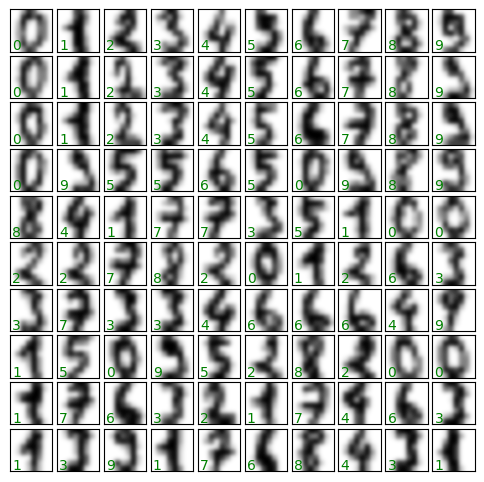

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(10, 10, figsize=(6, 6),
                         subplot_kw={'xticks':[], 'yticks':[]},
                         gridspec_kw=dict(hspace=0.1, wspace=0.1))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='binary', interpolation='gaussian')
    ax.text(0.05, 0.05, str(digits.target[i]), transform=ax.transAxes, color='green')

In [3]:
from sklearn.model_selection import train_test_split
splits = train_test_split(digits.images, digits.target, random_state=0)

In [4]:
import jax.numpy as jnp

In [5]:
images_train, images_test, label_train, label_test = map(jnp.asarray, splits)
print(f"{images_train.shape=} {label_train.shape=}")
print(f"{images_test.shape=}  {label_test.shape=}")

images_train.shape=(1347, 8, 8) label_train.shape=(1347,)
images_test.shape=(450, 8, 8)  label_test.shape=(450,)


In [6]:
from flax import nnx

In [7]:
x = images_train[0]
print(f"{x.shape=}") # 8 x 8
x = x.reshape(1, -1)
print(f"{x.shape=}") # 1 x 64

x.shape=(8, 8)
x.shape=(1, 64)


# Defining the Model

In [8]:
from flax import nnx

class SimpleNN(nnx.Module):

  def __init__(self, n_features: int = 64, n_hidden: int = 100,
               n_targets: int = 10, *, rngs: nnx.Rngs):
    self.n_features = n_features
    self.layer1 = nnx.Linear(n_features, n_hidden, rngs=rngs)
    self.layer2 = nnx.Linear(n_hidden, n_hidden, rngs=rngs)
    self.layer3 = nnx.Linear(n_hidden, n_targets, rngs=rngs)

  def __call__(self, x):
    x = x.reshape(x.shape[0], self.n_features) # Flatten images.
    x = nnx.selu(self.layer1(x))
    x = nnx.selu(self.layer2(x))
    x = self.layer3(x)
    return x

In [9]:
model = SimpleNN(rngs=nnx.Rngs(0))

nnx.display(model)  # Interactive display if penzai is installed.

In [10]:
import jax
import optax

In [11]:
optimizer = nnx.ModelAndOptimizer(model, optax.sgd(learning_rate=0.05))

In [12]:
def loss_fun(model: nnx.Module, data: jax.Array, labels: jax.Array):
  logits = model(data)
  loss = optax.softmax_cross_entropy_with_integer_labels(
    logits=logits, labels=labels
  ).mean()
  return loss, logits

In [13]:
@nnx.jit  # JIT-compile the function
def train_step(model: nnx.Module, optimizer: nnx.Optimizer, data: jax.Array,
    labels: jax.Array):
  loss_gradient = nnx.grad(loss_fun, has_aux=True)  # gradient transform!
  grads, logits = loss_gradient(model, data, labels)
  optimizer.update(grads)  # inplace update

In [14]:
train_step(model, optimizer, images_train, label_train)

In [15]:
x = images_train[0]
x = x.reshape(1, x.shape[-2], x.shape[-1])
print(f"{x.shape=}")

print(f"{label_train.shape=}")
y = label_train[0]
y = y.reshape(1)
print(f"{y.shape=}")

train_step(model, optimizer, x, y)

x.shape=(1, 8, 8)
label_train.shape=(1347,)
y.shape=(1,)


In [16]:
for i in range(301):  # 300 training epochs
  train_step(model, optimizer, images_train, label_train)
  if i % 50 == 0:  # Print metrics.
    loss, _ = loss_fun(model, images_test, label_test)
    print(f"epoch {i}: loss={loss:.2f}")

epoch 0: loss=29.15
epoch 50: loss=238.74
epoch 100: loss=187.43
epoch 150: loss=83.46
epoch 200: loss=17.40
epoch 250: loss=2.41
epoch 300: loss=2.31
